In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import models,layers
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

## Constants Declaration Area

In [121]:
IMAGE_SIZE = 256
CHANNELS = 3
BATCH_SIZE = 32
EPOCHS = 50
INPUT_SHAPE = (BATCH_SIZE , IMAGE_SIZE  , IMAGE_SIZE , CHANNELS)

## Load Dataset and View it.

In [7]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    directory="../Datasets/PlantVillage",
    batch_size=BATCH_SIZE,
    image_size=(IMAGE_SIZE,IMAGE_SIZE),
    shuffle=True,
)

Found 16011 files belonging to 10 classes.


In [13]:
class_names = dataset.class_names
class_num = len(class_names)
print("Number of classes : \n",class_num,"\nClass Names : \n", class_names)

Number of classes : 
 10 
Class Names : 
 ['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [18]:
for image_batch , label in dataset.take(1):
    print(f"Batch shape : {image_batch.shape}")
    print(f"Batch labels : {label}")

Batch shape : (32, 256, 256, 3)
Batch labels : [5 2 2 1 1 6 0 3 7 0 6 9 9 3 0 0 6 1 6 5 0 2 7 2 2 7 2 2 1 6 4 7]


### Ploting some images 

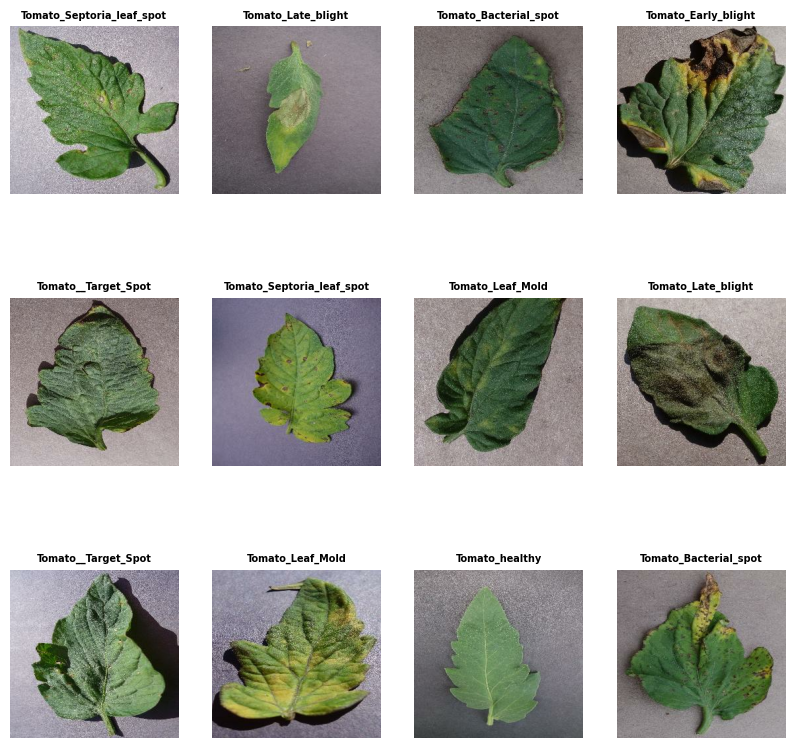

In [29]:
plt.figure(figsize=(10,10))
for image_batch , label_batch in dataset.take(1):
    for i in range (12):
        ax = plt.subplot(3,4,i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.axis("off")
        plt.title(class_names[label_batch[i].numpy()], fontsize=7 , fontweight='bold',)
    

## **DataSet Splitting **
**the dataset will be split as follow:** <br>
1- 70% ==> for training <br>
2- 10% ==> for validation <br>
3- 20% ==> for testing <br>

In [51]:
def dataset_spliting(ds , train_ratio =0.7, val_ratio = 0.1 , testing_ratio = 0.2):
    length=len(ds)
    train_ds = ds.take(int(length*train_ratio))
    test_ds = ds.skip(len(train_ds))
    val_ds = test_ds.take(int(length*val_ratio))
    test_ds = test_ds.skip(int(length*val_ratio))
    return train_ds,test_ds,val_ds

In [67]:
train_ds,test_ds,val_ds = dataset_spliting(dataset)
print("Size of the training dataset : " , len(train_ds) , " Batch")
print("Size of the validation dataset : " , len(val_ds) ,  " Batch")
print("Size of the testing dataset : " , len(test_ds) ,  " Batch")

Size of the training dataset :  350  Batch
Size of the validation dataset :  50  Batch
Size of the testing dataset :  101  Batch


## Cahcing and prefetching for our datasets for better optimization

In [70]:
train_ds = train_ds.cache().shuffle(len(train_ds) , reshuffle_each_iteration=True).prefetch(buffer_size=tf.data.AUTOTUNE)
train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

## Data Scaling and Image Resizing

In [71]:
scaling_resizing_layer = tf.keras.Sequential([
    #Resizing Layer
    layers.experimental.preprocessing.Resizing(IMAGE_SIZE,IMAGE_SIZE),
    # Rescaling Layer
    layers.experimental.preprocessing.Rescaling(1.0/255)
])

## Data Augmentation

In [72]:
data_augmentation_layer = tf.keras.Sequential([
    layers.experimental.preprocessing.RandomRotation(0.2),
    layers.experimental.preprocessing.RandomFlip("horizontal_and_vertical"),
    layers.experimental.preprocessing.RandomContrast(0.2),
    
])

## Model Training

In [123]:
model = tf.keras.Sequential([
    scaling_resizing_layer,
    data_augmentation_layer,
    layers.Conv2D(filters=32 , kernel_size=(3,3), input_shape=INPUT_SHAPE , activation="relu"),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(filters=64 , kernel_size=(3,3), activation="relu"),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(filters=64 , kernel_size=(3,3), activation="relu"),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(filters=64 , kernel_size=(3,3), activation="relu"),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(filters=64 , kernel_size=(3,3), activation="relu"),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(filters=64 , kernel_size=(3,3), activation="relu"),
    layers.MaxPool2D((2,2)),
    layers.Flatten(),
    layers.Dense(class_num,activation="softmax")
])

In [124]:
model.build(input_shape=INPUT_SHAPE)

In [125]:
model.summary()

Model: "sequential_16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential (Sequential)     (None, 256, 256, 3)       0         
                                                                 
 sequential_1 (Sequential)   (None, 256, 256, 3)       0         
                                                                 
 conv2d_28 (Conv2D)          (None, 254, 254, 32)      896       
                                                                 
 max_pooling2d_28 (MaxPoolin  (None, 127, 127, 32)     0         
 g2D)                                                            
                                                                 
 conv2d_29 (Conv2D)          (None, 125, 125, 64)      18496     
                                                                 
 max_pooling2d_29 (MaxPoolin  (None, 62, 62, 64)       0         
 g2D)                                                

In [126]:
model.compile(
    optimizer = "adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [127]:
history =  model.fit(
    x = train_ds,
    verbose = 1,
    batch_size = BATCH_SIZE,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/50
350/350 [==============================] - 151s 419ms/step - loss: 1.7708 - accuracy: 0.3607 - val_loss: 1.3877 - val_accuracy: 0.4894
Epoch 2/50
350/350 [==============================] - 150s 429ms/step - loss: 1.1731 - accuracy: 0.5849 - val_loss: 1.5072 - val_accuracy: 0.5525
Epoch 3/50
350/350 [==============================] - 143s 409ms/step - loss: 0.7996 - accuracy: 0.7209 - val_loss: 1.0919 - val_accuracy: 0.6812
Epoch 4/50
350/350 [==============================] - 144s 410ms/step - loss: 0.6333 - accuracy: 0.7827 - val_loss: 0.7284 - val_accuracy: 0.7513
Epoch 5/50
350/350 [==============================] - 146s 416ms/step - loss: 0.5089 - accuracy: 0.8276 - val_loss: 0.7325 - val_accuracy: 0.7644
Epoch 6/50
350/350 [==============================] - 146s 416ms/step - loss: 0.4365 - accuracy: 0.8492 - val_loss: 0.4250 - val_accuracy: 0.8525
Epoch 7/50
350/350 [==============================] - 141s 402ms/step - loss: 0.3793 - accuracy: 0.8669 - val_loss: 0.4555 -

In [147]:
model.evaluate(test_ds)

101/101 [==============================] - 11s 40ms/step - loss: 0.1376 - accuracy: 0.9576


[0.13755924999713898, 0.9576455950737]

In [149]:
def predict(model , image):
    img_array = tf.keras.preprocessing.image.img_to_array(image)
    img_array = tf.expand_dims(img_array, 0)
    preictions = model.predict(img_array , verbose=0)
    prediction_class = class_names[np.argmax(preictions[0])]
    confidence = round(100 * (np.max(preictions[0])) , 2)
    return prediction_class , confidence

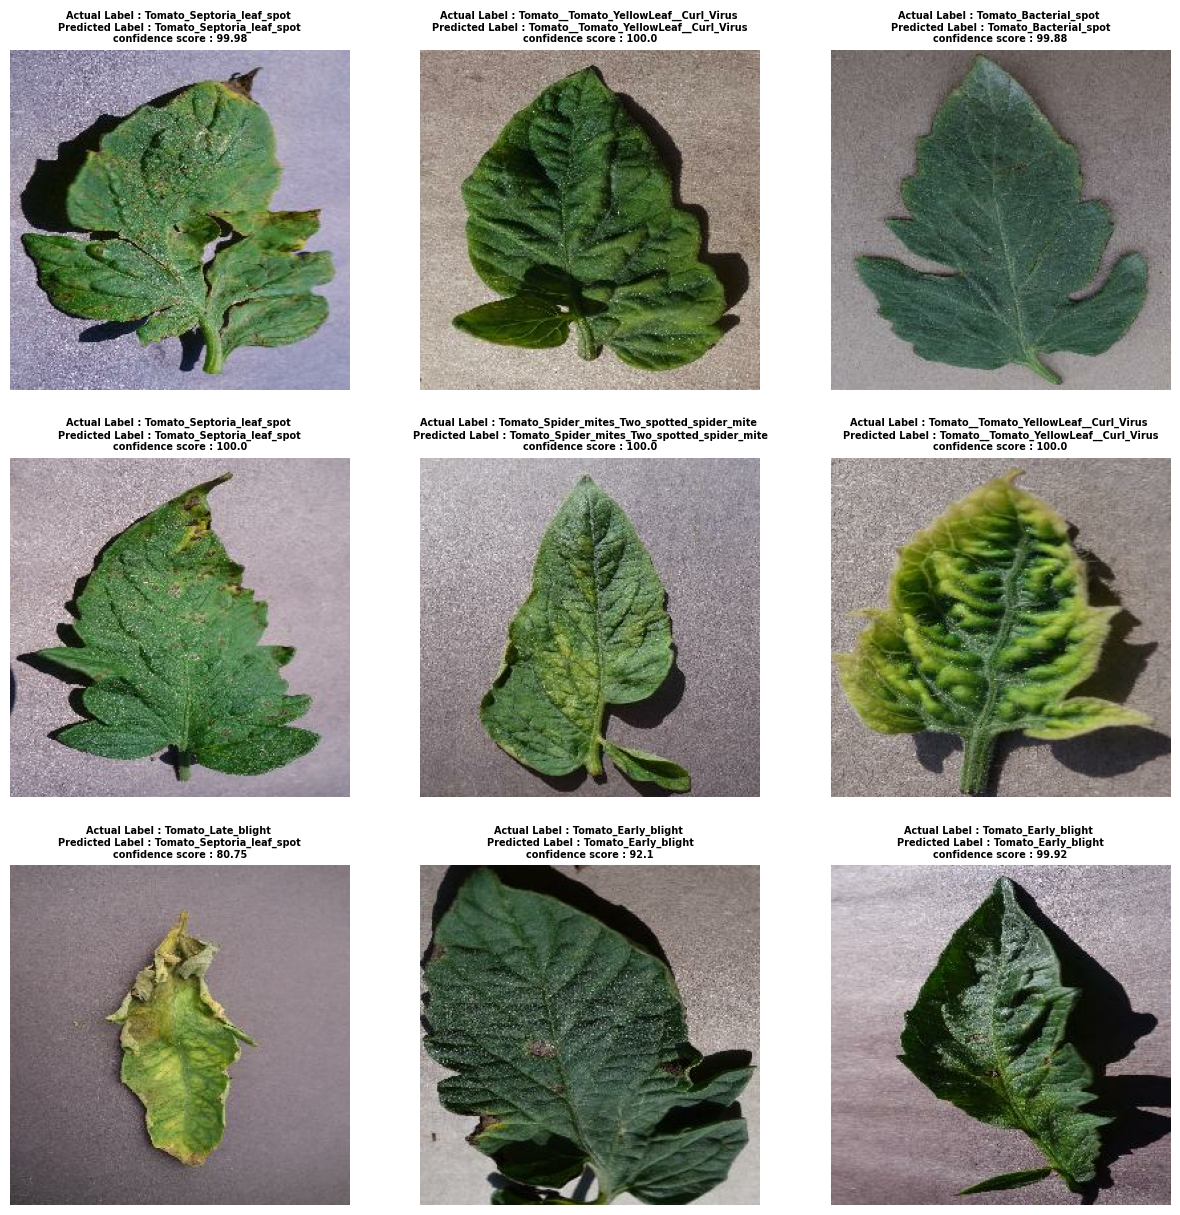

In [152]:
plt.figure(figsize=(15,15))
for image , label in test_ds.take(1):
    for i in range (9):
        ax = plt.subplot(3 , 3 , i+1)
        plt.imshow(image[i].numpy().astype("uint8"))
        plt.axis("off")
        prediction, confidence = predict(model , image[i].numpy())
        actual_label = class_names[label[i]]
        plt.title(f"Actual Label : {actual_label} \nPredicted Label : {prediction}\nconfidence score : {confidence}", fontsize=7 , fontweight='bold')


In [153]:
model_version = 1 
model.save(f"../Models/model_version_{model_version}")

INFO:tensorflow:Assets written to: ../Models/model_version_1\assets


INFO:tensorflow:Assets written to: ../Models/model_version_1\assets
